<a href="https://colab.research.google.com/github/rlaj0730-design/Text-Mining/blob/main/ex03_%EC%9D%8C%EC%95%85_%EC%B6%94%EC%B2%9C_%EA%B8%B0%EB%8A%A5_%EA%B5%AC%ED%98%84.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 추천 시스템이란?

> 사용자(USER)에게 관련된 아이템(item)을 추천해주는 것


> 추천 시스템 사례
- e-commerce: 쿠팡과 같은 온라인 쇼핑몰에서 고객의 구매 이력과 검색 이력을 바탕으로 제품을 추천
- 스트리밍 서비스: 넷플릭스, 유튜브, 스포티파이 등에서 사용자의 시청/청취 이력을 바탕으로 영화, 동영상, 음악을 추천
- 뉴스 포털: 사용자가 관심을 가질 만한 뉴스 기사를 추천 등

# 추천 시스템의 종류

<img src = "https://oopy.lazyrockets.com/api/v2/notion/image?src=https%3A%2F%2Fprod-files-secure.s3.us-west-2.amazonaws.com%2Fa21ec021-5399-43b4-839c-6d528586f469%2F413979b5-e77a-4847-b4b2-39e1e48b2cbd%2FUntitled.png&blockId=0761ae34-9a21-4e71-a541-a287f07c7310"/>





## 1. 콘텐츠 기반 필터링 (Content-Based Filtering)

- 사용자가 과거에 선호했던 **아이템의 특성(장르, 키워드 등)** 을 분석하여 비슷한 아이템을 추천하는 방식


---

## 2. 협업 필터링 (Collaborative Filtering)

- 여러 사용자의 **평점, 구매, 클릭 등 행동 데이터**를 활용하여 선호도를 예측하고 추천하는 방식

### 2-1. 기억 기반(Memory-Based) 협업 필터링

- 사용자 또는 아이템 간의 **유사도(Similarity)** 를 직접 계산하여 추천하는 방식

**① 사용자 기반 (User-Based)**
- 나와 취향이 비슷한 사용자가 좋아한 아이템을 추천

**② 아이템 기반 (Item-Based)**
- 사용자들에게 비슷한 평가를 받은 아이템을 추천

### 2-2. 모델 기반(Model-Based) 협업 필터링

- 사용자와 아이템의 **행동 패턴을 학습하여 선호도를 예측**하는 방식
- **잠재 요인(Latent Factor)** : 사용자와 아이템에 숨어 있는 취향이나 특성
- **행렬 분해(Matrix Factorization)** : 사용자와 아이템의 잠재 요인을 학습하는 대표적인 방법

---

## 3. 하이브리드 방식 (Hybrid Filtering)

- **콘텐츠 기반 필터링과 협업 필터링 등 여러 추천 방식**을 결합하는 방법
- 각 방식의 단점을 보완하여 개인화된 추천 성능 향상


# 콘텐츠 기반 필터링 (Contents-Based Filtering)

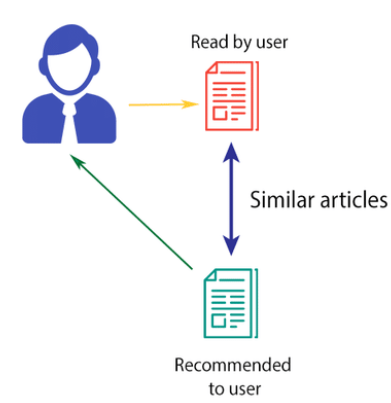


- 사용자가 과거에 선호했던 **아이템의 특성(Content)** 을 분석하여 비슷한 아이템을 추천하는 방식
- 다른 사용자의 데이터보다는 **해당 사용자의 취향과 아이템 자체의 특징**을 중심으로 추천
- 아이템 간의 **유사도를 기반으로 비교적 쉽게 구현 가능**
- 사용자가 기존에 선호했던 것과 비슷한 아이템 위주로 추천되기 때문에  
  **새로운 취향의 아이템을 발견하기 어렵다는 한계**가 있음

### 추천 과정

1. 사용자가 과거에 선호하거나 이용한 아이템을 확인
2. 해당 아이템이 가진 **특징(Feature)** 을 추출
   - 영화 → 장르, 배우, 감독, 줄거리 등
   - 음악 → 장르, 가수, 가사 등
   - 뉴스 → 제목, 본문, 키워드 등
3. 다른 아이템과의 **유사도(Similarity)** 를 계산
4. 유사도가 높은 아이템을 사용자에게 추천

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks/동아 텍스트마이닝

/content/drive/MyDrive/Colab Notebooks/동아 텍스트마이닝


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# 실습 파일 불러오기!

# lyrics_by_year_1964_2023.csv
df = pd.read_csv("./data/lyrics_by_year_1964_2023.csv")
df.head()
# 1964~2023년 사이의 MELON 연도별 TOP 100 노래 데이터

,id,year,title,singer,lyric,x_rated
0,30072384,1964,워싱턴광장,정 시스터즈,NaN,False
1,8150699,1964,황혼의 에레지,최양숙,NaN,False
2,5758967,1964,물새우는 해변,권혜경,고요한 밤하늘에 별이 잠들고\n밀리는 파도소리 나혼자 들으며\n외로히 홀로 날으는 ...,False
3,4083218,1964,내일또 만납시다,금호동,하루의 일을 끝내고 돌아가는\n거리엔 사람의 물결\n하늘엔 별이 하나 둘 반짝이면\...,False
4,3622464,1964,밀짚모자 목장아가씨,박재란,시원한 밀짚모자\n포플라 그늘에\n양떼를 몰고가는\n목장의 아가씨\n연분홍 빛 입술...,False


| 컬럼명 | 설명 |
| --- | --- |
| id | 각 노래의 고유 식별자 |
| year | 노래가 발표된 연도 |
| title | 노래 제목 |
| singer | 노래 가수 이름 |
| lyric | 노래 가사 |
| x_rated | X-rated(성인 등급) 여부 |

In [ ]:
# df 정보 확인해서 결측치 확인
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4666 entries, 0 to 4665
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   id       4666 non-null   int64 
 1   year     4666 non-null   int64 
 2   title    4666 non-null   object
 3   singer   4666 non-null   object
 4   lyric    4458 non-null   object
 5   x_rated  4666 non-null   bool  
dtypes: bool(1), int64(2), object(3)
memory usage: 187.0+ KB


In [ ]:
# 결측치가 있는 행 삭제 후 인덱스 재설정
df = df.dropna().reset_index(drop=True)

# reset_index() : 인덱스를 0부터 다시 설정
# drop=True : 기존 인덱스를 새로운 컬럼으로 추가하지 않고 삭제

In [ ]:
# 결측치 삭제 됐는지 확인
df.isnull().sum()

,0
id,0
year,0
title,0
singer,0
lyric,0
x_rated,0


## 가사(lyric)를 활용한 유사도 기반 추천 시스템 만들어보기!
### 추천 시스템 구현 과정

1. 가사 데이터 전처리
   - 특수문자 제거 → 띄어쓰기 교정 → 형태소 분석 및 품사 태깅 → 불용어 제거

2. 가사 데이터 벡터화

3. 곡 간 유사도 계산 -> 유사도가 높은 곡 추출

5. 유사 음악 추천 시스템 구현

### 1. 전처리
- 특수문자 제거 → 정규표현식 활용

In [ ]:
import re

In [ ]:
# re 모듈 활용해서 영어(대소문자), 숫자, 한글, 띄어쓰기, 온점, 물음표, 느낌표 제외한 특수문자 제거
pattern = r"[^a-zA-Z0-9가-힣\s\.\?\!]"

# ^       : [] 안에서 사용하면 '해당 문자를 제외한 나머지'라는 의미
# a-z     : 영어 소문자
# A-Z     : 영어 대문자
# 0-9     : 숫자
# 가-힣   : 한글
# \s      : 띄어쓰기
# \.      : 온점(.)
# \?      : 물음표(?)
# \!      : 느낌표(!)

In [ ]:
# 정제된 가사를 cleaned_lyric 이라는 새로운 컬럼에 추가해보자!
# 가사 정제 후 새로운 list에 넣어주기
cleaned_lyrics = [re.sub(pattern, "", lyric) for lyric in df["lyric"]]

# re.sub(패턴, 바꿀 값, 대상 문자열)
# → pattern에 해당하는 특수문자를 찾아 빈 문자열("")로 변경하여 제거

# cleaned_lyrics = []
#
# for lyric in df["lyric"]:
#     cleaned_lyric = re.sub(pattern, "", lyric)
#     cleaned_lyrics.append(cleaned_lyric)

In [ ]:
cleaned_lyrics[:5]

['고요한 밤하늘에 별이 잠들고\n밀리는 파도소리 나혼자 들으며\n외로히 홀로 날으는 물새의 울음소리\n쓸쓸한 내 마음 속에 슬픔을 주네\n고요한 밤하늘에 별이 잠들고\n밀리는 파도소리 나혼자 들으며\n외로히 홀로 날으는 물새의 울음소리\n쓸쓸한 내 마음 속에 슬픔을 주네\n',
 '하루의 일을 끝내고 돌아가는\n거리엔 사람의 물결\n하늘엔 별이 하나 둘 반짝이면\n가로등 하나 둘 꽃 피네\n허공을 스치는 바람은 차고\n흐뭇한 마음은 애드베룬\n가벼운 발길 헤어질 때 인사는\n내일 또 다시 만납시다\n하루의 일을 끝내고 돌아가는\n거리엔 사람의 물결\n하늘엔 별이 하나 둘 반짝이면\n가로등 하나 둘 꽃 피네\n허공을 스치는 바람은 차고\n흐뭇한 마음은 애드베룬\n가벼운 발길 헤어질 때 인사는\n내일 또 다시 만납시다\n내일 또 다시 만납시다\n',
 '시원한 밀짚모자\n포플라 그늘에\n양떼를 몰고가는\n목장의 아가씨\n연분홍 빛 입술에는\n살며시 웃음 띄우고\n넓다란 푸른 목장\n하늘에 구름가네\n라라라 라라라라라\n라라라라 라라라라\n라라라 라라라라라\n라라라라 라라라라\n연분홍 빛 입술에는\n살며시 웃음 띄우고\n넓다란 푸른 목장\n하늘에 구름가네\n구름가네 음음음음\n',
 '비가 나리네 비가 나리네\n돌아선 이가슴에\n그님은 어데 그어느곳에\n이마음 벗사려 떨어져가도\n이마음 몹쓸건 미련때문에\n아 몸부림치며 님을 불렀네\n이마음 모질게 헤어져가고\n이마음 몹쓸건 미련때문에\n아 목놓아 울며 님을 불렀네\n',
 '잊지 못할 빗속의 여인\n지금은 어데 있나\n\n노오란 레인코트에\n검은 눈동자 잊지 못하네\n\n다정하게 미소지며\n검은 우산을 받쳐주네\n나리는 빗방울 바라보며\n말없이 말없이 걸었네\n\n잊지 못할 빗속의 여인\n그 여인을 잊지 못하네\n\n다정하게 미소지며\n검은 우산을 받쳐주네\n나리는 빗방울 바라보며\n말없이 말없이 걸었네\n\n잊지 못할 빗 속의 여인\n그 여인을 잊지 못하네\n\n오 잊지 못할 빗 속의 여인\n그 여인을 잊지 못

In [ ]:
df["cleaned_lyrics"] = cleaned_lyrics
df.head()

,id,year,title,singer,lyric,x_rated,cleaned_lyrics
0,5758967,1964,물새우는 해변,권혜경,고요한 밤하늘에 별이 잠들고\n밀리는 파도소리 나혼자 들으며\n외로히 홀로 날으는 ...,False,고요한 밤하늘에 별이 잠들고\n밀리는 파도소리 나혼자 들으며\n외로히 홀로 날으는 ...
1,4083218,1964,내일또 만납시다,금호동,하루의 일을 끝내고 돌아가는\n거리엔 사람의 물결\n하늘엔 별이 하나 둘 반짝이면\...,False,하루의 일을 끝내고 돌아가는\n거리엔 사람의 물결\n하늘엔 별이 하나 둘 반짝이면\...
2,3622464,1964,밀짚모자 목장아가씨,박재란,시원한 밀짚모자\n포플라 그늘에\n양떼를 몰고가는\n목장의 아가씨\n연분홍 빛 입술...,False,시원한 밀짚모자\n포플라 그늘에\n양떼를 몰고가는\n목장의 아가씨\n연분홍 빛 입술...
3,3621978,1964,아빠 안녕,현미,비가 나리네 비가 나리네\n돌아선 이가슴에\n그님은 어데 그어느곳에\n이마음 벗사려...,False,비가 나리네 비가 나리네\n돌아선 이가슴에\n그님은 어데 그어느곳에\n이마음 벗사려...
4,2517558,1964,빗속의 여인 1964년작,Add 4 신중현,잊지 못할 빗속의 여인\n지금은 어데 있나\n\n노오란 레인코트에\n검은 눈동자 잊...,False,잊지 못할 빗속의 여인\n지금은 어데 있나\n\n노오란 레인코트에\n검은 눈동자 잊...


In [ ]:
# 원본 가사와 정제된 가사가 다른 행만 가져오기
df[df["lyric"] != df["cleaned_lyrics"]]

,id,year,title,singer,lyric,x_rated,cleaned_lyrics
101,1003933,1968,딜라일라,조영남,i saw the light on the night\nthat i passed by...,False,i saw the light on the night\nthat i passed by...
112,46264,1968,아카시아 이별,이영숙,아카시아 꽃 냄새 풍기는 이 길은\n옛사랑 그리워지는 추억이 잠든 길\n아카시아 꽃...,False,아카시아 꽃 냄새 풍기는 이 길은\n옛사랑 그리워지는 추억이 잠든 길\n아카시아 꽃...
236,2329512,1973,행복의 나라,양희은,라\n장막을 걷어라\n너의 좁은 문으로 이 세상을 떠보자\n창문을 열어라\n춤추는 ...,False,라\n장막을 걷어라\n너의 좁은 문으로 이 세상을 떠보자\n창문을 열어라\n춤추는 ...
272,1925230,1974,저꽃속에 찬란한 빛이,박경희,어둠에 묻혀 흘러간 그 세월의 눈물은\n사랑을 잃어 흩어진 옛 추억의 그림자\n잊을...,False,어둠에 묻혀 흘러간 그 세월의 눈물은\n사랑을 잃어 흩어진 옛 추억의 그림자\n잊을...
288,539543,1974,피리부는 사나이,송창식,나는 피리 부는 사나이\n바람 따라 가는 떠도는 떠돌이\n멋진 피리 하나 들고 다닌...,False,나는 피리 부는 사나이\n바람 따라 가는 떠도는 떠돌이\n멋진 피리 하나 들고 다닌...
...,...,...,...,...,...,...,...
4443,34270805,2023,오르트구름,윤하 YOUNHA,어둠만이 나의 전부였던 동안\n숨이 벅차도록 달려왔잖아\nNever say “tim...,False,어둠만이 나의 전부였던 동안\n숨이 벅차도록 달려왔잖아\nNever say time...
4445,33666269,2023,Permission to Dance,방탄소년단,It’s the thought of being young\nWhen your hea...,False,Its the thought of being young\nWhen your hear...
4446,33507137,2023,Butter,방탄소년단,Smooth like butter\nLike a criminal undercover...,False,Smooth like butter\nLike a criminal undercover...
4449,32872978,2023,Dynamite,방탄소년단,Cos ah ah\nI’m in the stars tonight\nSo watch ...,False,Cos ah ah\nIm in the stars tonight\nSo watch m...


In [ ]:
# 전처리 전
print(df.loc[4443, "lyric"])

print("\n========== 전처리 후 ==========\n")

# 전처리 후
print(df.loc[4443, "cleaned_lyrics"])

어둠만이 나의 전부였던 동안
숨이 벅차도록 달려왔잖아
Never say “time’s up”
경계의 끝자락
내 끝은 아니니까

울타리 밖에 일렁이는 무언가
그 아무도 모르는 별일지 몰라
I wanna wanna be there
I’m gonna gonna be there
벅찬 맘으로 이 궤도를 벗어나

Let’s go
새로운 길의 탐험가
Beyond the road
껍질을 깨뜨려버리자
두려움은 이제 거둬
오로지 나를 믿어
지금이 바로 time to fly

두 눈 앞의 끝 사뿐 넘어가
한계 밖의 trip 짜릿하잖아
녹이 슨 심장에 쉼 없이 피는 꿈
무모하대도 믿어 난


누구도 본 적 없는 낯선 우주 속에
겁 없이 뛰어들어 fall (fall) fall (fall)
답답한 가슴 안에
불꽃을 피워낼래
shine and bright

곧 잡힐 듯이 반짝이던 무언가
꼭 달릴수록 멀어져도 난 좋아
I never never give up
I’m getting getting better
여정은 이미 시작된 지 오래야

Let’s go
끝이라 생각한 순간
Beyond the road
넓은 세상이 날 감싸 안아
때로는 느릿해도
가끔은 지친대도
멈추지 않고 let me fly

두 눈 앞의 끝 사뿐 넘어가
한계 밖의 trip 짜릿하잖아
녹이 슨 심장에 쉼 없이 피는 꿈
무모하대도 믿어 난

누가 뭐래도 믿어 난

Go 다치고 망가져 버거워진 항해
Go 숨 한 번 고르고 이어가면 OK
구름 너머 세상을 내 품에 안을래

두 눈 앞의 끝 사뿐 넘어가
한계 밖의 trip 짜릿하잖아
녹이 슨 심장에 쉼 없이 피는 꿈
무모하대도 믿어 난

나의 여정을 믿어 난

========== 전처리 후 ==========

어둠만이 나의 전부였던 동안
숨이 벅차도록 달려왔잖아
Never say times up
경계의 끝자락
내 끝은 아니니까

울타리 밖에 일렁이는 무언가
그 아무도 모르는 별일지 몰라
I wanna wanna be there
Im gonna gonna be there
벅찬 맘으로

- 형태소 분석 및 불용어 처리
  - 형태소 분석과 불용어 처리를 통해 가사에서 의미 있는 단어를 추출하고 불필요한 단어를 제거하여, 곡 간의 유사도를 보다 의미 있게 계산하기 위한 전처리 과정

In [ ]:
# 1. 도구 설치 필요
# kiwipiepy, konlpy 설치
!pip -q install kiwipiepy konlpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 MB 10.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 105.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 81.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 438.5/438.5 kB 33.4 MB/s eta 0:00:00


In [ ]:
# 2. kiwi에서 불용어 리스트 가져오기
from kiwipiepy.utils import Stopwords

# 2-1. 불용어 사전 객체 초기화
stopwords = Stopwords()

# 2-2. 불용어 사전의 단어들만 추출
stopwords_list = [word for word, tag in stopwords.stopwords]

In [ ]:
stopwords_list

['지만',
 '하',
 '되',
 '적',
 'ᆫ',
 '그',
 '때문',
 '않',
 '에서',
 '위하',
 '와',
 '로',
 '겠',
 'ᆫ',
 '으로',
 'ᆯ',
 '받',
 '제',
 '는',
 '어야',
 '다는',
 '과',
 '를',
 '사람',
 '이',
 '라는',
 '지',
 '보',
 '다',
 '만',
 '이',
 '며',
 '중',
 '성',
 '하',
 '기',
 '이',
 '까지',
 '던',
 '에',
 '어',
 '다고',
 '어서',
 '어',
 '그',
 '었',
 '만',
 'ᆫ다',
 '와',
 '은',
 '지',
 '지역',
 '일',
 '월',
 '있',
 '과',
 '하',
 '면서',
 '아니',
 '도',
 '년',
 '되',
 '통하',
 '을',
 '때',
 '게',
 '라',
 '이',
 '들',
 '우리',
 '있',
 '이',
 '을',
 '대하',
 '의',
 '주',
 '는',
 '나',
 '고',
 '화',
 '부터',
 '한',
 '같',
 '면',
 '없',
 '따르',
 '수',
 '원',
 '등',
 '더',
 '하',
 '일',
 '에게',
 '가',
 '것',
 '명',
 '고',
 '은',
 '말',
 '다']

In [ ]:
# 3. Okt, Kiwi 형태소 분석기 객체 생성
from kiwipiepy import Kiwi
from konlpy.tag import Okt

okt = Okt() # 형태소 분석(품사 태깅)
kiwi = Kiwi() # 띄어쓰기 교정용

활용할 품사 : Adjective(형용사), Verb(동사), Adverb(부사), Exclamation(감탄사)

In [ ]:
# 4. 토큰화 함수 정의 → pos_tagging(text)
def pos_tagging(text) :
  # 4-1. 띄어쓰기 교정
  text = kiwi.space(text)

  # 4-2. 품사 태깅(형태소 분석)
  pos_words = okt.pos(text, stem=True, norm=True)

  # 4-3. 원하는 품사만 추출 + 불용어 제거
  tagged_list = []
  for word, tag in pos_words :
    if tag in ["Adjective", "Verb", "Adverb", "Exclamation"] :
      if word not in stopwords_list :
        tagged_list.append(word)
  return tagged_list

In [ ]:
# 5. 함수 작동 테스트 (첫번째줄 가사 뽑아서)
pos_tagging(df["cleaned_lyrics"].iloc[0])

['잠들다',
 '밀리다',
 '들다',
 '외롭다',
 '날다',
 '쓸쓸하다',
 '잠들다',
 '밀리다',
 '들다',
 '외롭다',
 '날다',
 '쓸쓸하다']

In [ ]:
# 6. 전체 데이터 적용
# 약 5분 소요
from tqdm import tqdm
tagged_lyric = [pos_tagging(text) for text in tqdm(df["cleaned_lyrics"])]

# tagged_lyric = []

# for text in tqdm(df["cleaned_lyrics"]):
#     result = pos_tagging(text)
#    tagged_lyric.append(result)

100%|██████████| 4458/4458 [04:30<00:00, 16.47it/s]


In [ ]:
# 7. tagged_lyric 새로운 컬럼에 저장
df["tagged_lyric"] = tagged_lyric

In [ ]:
df.head()

,id,year,title,singer,lyric,x_rated,cleaned_lyrics,tagged_lyric
0,5758967,1964,물새우는 해변,권혜경,고요한 밤하늘에 별이 잠들고\n밀리는 파도소리 나혼자 들으며\n외로히 홀로 날으는 ...,False,고요한 밤하늘에 별이 잠들고\n밀리는 파도소리 나혼자 들으며\n외로히 홀로 날으는 ...,"[잠들다, 밀리다, 들다, 외롭다, 날다, 쓸쓸하다, 잠들다, 밀리다, 들다, 외롭..."
1,4083218,1964,내일또 만납시다,금호동,하루의 일을 끝내고 돌아가는\n거리엔 사람의 물결\n하늘엔 별이 하나 둘 반짝이면\...,False,하루의 일을 끝내고 돌아가는\n거리엔 사람의 물결\n하늘엔 별이 하나 둘 반짝이면\...,"[끝내다, 돌아가다, 반짝이다, 스치다, 흐뭇하다, 가볍다, 헤어지다, 만나다, 끝..."
2,3622464,1964,밀짚모자 목장아가씨,박재란,시원한 밀짚모자\n포플라 그늘에\n양떼를 몰고가는\n목장의 아가씨\n연분홍 빛 입술...,False,시원한 밀짚모자\n포플라 그늘에\n양떼를 몰고가는\n목장의 아가씨\n연분홍 빛 입술...,"[시원하다, 몰다, 가다, 살며시, 띄우다, 넓다, 가다, 살며시, 띄우다, 넓다,..."
3,3621978,1964,아빠 안녕,현미,비가 나리네 비가 나리네\n돌아선 이가슴에\n그님은 어데 그어느곳에\n이마음 벗사려...,False,비가 나리네 비가 나리네\n돌아선 이가슴에\n그님은 어데 그어느곳에\n이마음 벗사려...,"[돌아서다, 어느, 떨어지다, 아, 부르다, 모질다, 헤어지다, 가다, 아, 놓다,..."
4,2517558,1964,빗속의 여인 1964년작,Add 4 신중현,잊지 못할 빗속의 여인\n지금은 어데 있나\n\n노오란 레인코트에\n검은 눈동자 잊...,False,잊지 못할 빗속의 여인\n지금은 어데 있나\n\n노오란 레인코트에\n검은 눈동자 잊...,"[잊다, 하다, 있다, 놓다, 검다, 잊다, 하다, 다정하다, 지다, 검다, 받치다..."


In [ ]:
# pickle
# : 파이썬 객체(DataFrame, 리스트, 딕셔너리 등)를
#   객체의 형태를 유지한 채 파일로 저장하고 다시 불러올 수 있도록 해주는 모듈

import pickle

# 형태소 분석 및 불용어 처리가 완료된 DataFrame을 pickle 파일로 저장
# wb(write binary) : 바이너리 파일을 쓰기 모드로 열기
with open("./data/tagged_lyrics.pkl", "wb") as f:

    # pickle.dump(저장할 객체, 파일)
    # → df 객체를 tagged_lyrics.pkl 파일에 저장
    pickle.dump(df, f)

### 전처리 및 토큰화 완료!

In [ ]:
# 임베딩 진행 → gensim
!pip -q install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 64.4 MB/s eta 0:00:00


In [ ]:
import pickle

with open("./data/tagged_lyrics.pkl", "rb") as f :
  df = pickle.load(f)

In [ ]:
df

,id,year,title,singer,lyric,x_rated,cleaned_lyrics,tagged_lyric
0,5758967,1964,물새우는 해변,권혜경,고요한 밤하늘에 별이 잠들고\n밀리는 파도소리 나혼자 들으며\n외로히 홀로 날으는 ...,False,고요한 밤하늘에 별이 잠들고\n밀리는 파도소리 나혼자 들으며\n외로히 홀로 날으는 ...,"[잠들다, 밀리다, 들다, 외롭다, 날다, 쓸쓸하다, 잠들다, 밀리다, 들다, 외롭..."
1,4083218,1964,내일또 만납시다,금호동,하루의 일을 끝내고 돌아가는\n거리엔 사람의 물결\n하늘엔 별이 하나 둘 반짝이면\...,False,하루의 일을 끝내고 돌아가는\n거리엔 사람의 물결\n하늘엔 별이 하나 둘 반짝이면\...,"[끝내다, 돌아가다, 반짝이다, 스치다, 흐뭇하다, 가볍다, 헤어지다, 만나다, 끝..."
2,3622464,1964,밀짚모자 목장아가씨,박재란,시원한 밀짚모자\n포플라 그늘에\n양떼를 몰고가는\n목장의 아가씨\n연분홍 빛 입술...,False,시원한 밀짚모자\n포플라 그늘에\n양떼를 몰고가는\n목장의 아가씨\n연분홍 빛 입술...,"[시원하다, 몰다, 가다, 살며시, 띄우다, 넓다, 가다, 살며시, 띄우다, 넓다,..."
3,3621978,1964,아빠 안녕,현미,비가 나리네 비가 나리네\n돌아선 이가슴에\n그님은 어데 그어느곳에\n이마음 벗사려...,False,비가 나리네 비가 나리네\n돌아선 이가슴에\n그님은 어데 그어느곳에\n이마음 벗사려...,"[돌아서다, 어느, 떨어지다, 아, 부르다, 모질다, 헤어지다, 가다, 아, 놓다,..."
4,2517558,1964,빗속의 여인 1964년작,Add 4 신중현,잊지 못할 빗속의 여인\n지금은 어데 있나\n\n노오란 레인코트에\n검은 눈동자 잊...,False,잊지 못할 빗속의 여인\n지금은 어데 있나\n\n노오란 레인코트에\n검은 눈동자 잊...,"[잊다, 하다, 있다, 놓다, 검다, 잊다, 하다, 다정하다, 지다, 검다, 받치다..."
...,...,...,...,...,...,...,...,...
4453,31343875,2023,첫사랑,백아,알아 내 맘에 조용히\n문을 두드리면\n눈에 뿌옇게 고여버린\n널 흘려보내야 해\n...,False,알아 내 맘에 조용히\n문을 두드리면\n눈에 뿌옇게 고여버린\n널 흘려보내야 해\n...,"[조용하다, 두드리다, 뿌옇다, 버리다, 흘리다, 보내다, 빠르다, 놓치다, 알아보..."
4454,30962526,2023,모든 날 모든 순간 Every day Every Moment,폴킴,네가 없이 웃을 수 있을까\n생각만 해도 눈물이나\n힘든 시간 날 지켜준 사람\n이...,False,네가 없이 웃을 수 있을까\n생각만 해도 눈물이나\n힘든 시간 날 지켜준 사람\n이...,"[없이, 있다, 힘드다, 지키다, 대다, 지키다, 품다, 따뜻하다, 하다, 유일하다..."
4455,30244931,2023,봄날,방탄소년단,보고 싶다\n이렇게 말하니까 더 보고 싶다\n너희 사진을 보고 있어도\n보고 싶다\...,False,보고 싶다\n이렇게 말하니까 더 보고 싶다\n너희 사진을 보고 있어도\n보고 싶다\...,"[싶다, 이렇게, 싶다, 있다, 싶다, 너무, 야속하다, 밉다, 하다, 보다, 힘들..."
4456,4446485,2023,너의 모든 순간,성시경,이윽고 내가 한눈에\n너를 알아봤을 때\n모든 건 분명 달라지고 있었어\n내 세상은...,False,이윽고 내가 한눈에\n너를 알아봤을 때\n모든 건 분명 달라지고 있었어\n내 세상은...,"[알아보다, 달라지다, 있다, 알다, 나뉘다, 따스하다, 불어오다, 웃다, 눈부시다..."


### 2. 벡터화

#### 1) Doc2vec란?
 - Word2vec은 단어 하나를 하나의 vector화 (2013년 제안)
   - 주요 모델 : CBOW, Skip Gram
 - Doc2vec은 문서 하나를 하나의 vector화 (2015년 제안)
   - 주요 모델 : PV-DM model, PV-DBoW

<center>  
<img src="https://arome1004.cafe24.com/images/machine_learning/dcx03.png" width=60%>   
</center>

#### Doc2Vec의 주요 학습 방식

Doc2Vec은 각 문서에 **Document ID**를 부여하고,  
각 ID에 연결된 **Document Vector(문서 벡터)** 를 학습하여 문서의 특징을 벡터로 표현함.

- **Document ID** : 각 문서를 구분하기 위한 이름표
- **Document Vector** : 각 Document ID에 연결되어 학습되는 숫자 벡터
  - 처음에는 의미 없는 값으로 시작
  - 단어를 예측하는 학습을 반복하면서 해당 문서의 특징을 반영하도록 값이 수정됨
  - 학습이 완료된 Document Vector를 해당 문서를 대표하는 벡터로 사용

---

#### DM (Distributed Memory)

**: 문서 정보 + 주변 단어를 이용하여 중심 단어를 예측하는 방식**

- Document ID에 연결된 **문서 벡터**와 주변 단어의 **단어 벡터**를 함께 입력으로 사용
- 입력된 정보를 이용하여 특정 단어를 예측
- 실제 단어와 예측 결과를 비교하면서 예측을 잘할 수 있도록 벡터 값을 반복해서 수정
- 이 과정에서 Document Vector에도 해당 문서의 특징이 점차 반영됨

→ **문서 정보와 주변 문맥을 함께 활용하여 문서 벡터를 표현**

→ **Document ID뿐만 아니라 주변 단어의 정보까지 함께 활용하기 때문에 문서의 문맥적 특징을 보다 풍부하게 학습할 수 있어, 일반적으로 DBOW보다 좋은 성능을 보일 수 있음**

---

#### DBOW (Distributed Bag of Words)

**문서 정보만 이용하여 해당 문서에 등장하는 단어를 랜덤하게 예측하는 방식**

- 주변 단어를 입력으로 사용하지 않고 **Document ID에 연결된 문서 벡터**를 입력으로 사용
- Document Vector를 이용하여 단어를 예측하고, 예측 결과와 실제 단어를 비교
- 해당 문서의 단어를 잘 예측할 수 있도록 Document Vector의 값을 반복해서 수정

→ **문서에 어떤 단어들이 등장하는지를 학습하면서 문서 벡터를 표현**


In [ ]:
# 필요한 도구들 불러오기
import gensim
from gensim.models.doc2vec import TaggedDocument

# TaggedDocument
# : Doc2Vec 학습을 위해 각 문서의 단어(words)와
#   문서를 구분할 ID(tags)를 함께 지정해주는 클래스

# 가사 + 가사의 이름표(Document ID)를 하나로 묶어서 Doc2Vec 학습용 데이터로 만들어주는 것

In [ ]:
# TaggedDocument 사용해보기
TaggedDocument(
    tags = ["document 0"], # 각 문서를 구분할 수 있는 태그(문서 ID)
    words = df["tagged_lyric"][0]
)
# tags의 경우, 리스트로 묶어서 여러 문서 태그를 부여할 수 있지만
# 보통은 문서별로 하나의 태그만 사용하는 경우가 많음

TaggedDocument(words=['잠들다', '밀리다', '들다', '외롭다', '날다', '쓸쓸하다', '잠들다', '밀리다', '들다', '외롭다', '날다', '쓸쓸하다'], tags=['document 0'])

In [ ]:
# 하나 하나씩 TaggedDocument로 변환

tagged_corpus_list = [] # 변환된 결과 쌓아주는 리스트

# 형태소 분석된 가사를 하나씩 가져오면서 순서 번호(i)도 함께 가져오기
for i, tokens in enumerate(df["tagged_lyric"]):

    # 순서 번호를 이용하여 각 문서의 고유한 ID 생성
    tag = f"document {i}"

    # 가사(words)와 문서 ID(tags)를 하나로 묶기
    tagged_doc = TaggedDocument(
        tags=[tag],
        words=tokens
    )

    # 변환된 문서를 리스트에 하나씩 추가
    tagged_corpus_list.append(tagged_doc)

In [ ]:
len(tagged_corpus_list)

4458

#### 2) doc2vec 학습

In [ ]:
from gensim.models.doc2vec import Doc2Vec

In [ ]:
# doc2vec 모델 초기화
model = Doc2Vec(
    vector_size = 300, # 학습할 벡터(임베딩)의 차원 수(하나의 문서를 몇 개의 숫자로 표현할 것인지)
    alpha = 0.025,     # 초기 학습률
    # 학습하면서 벡터 값을 수정할 때 한 번에 얼마나 크게 수정할 것인지
    # alpha가 크면 한 번에 비교적 크게 수정하고, 작으면 조금씩 수정
    min_alpha=0.001,   # 학습 진행 중에 점차 감소시킬 최소 학습률
    window = 8,         # 주변 단어 범위 설정
    # 중심 단어를 기준으로 좌우 최대 8칸까지의 단어를 주변 문맥으로 설정
    min_count=2,       # 최소 등장 횟수(전체 가사 데이터에서 몇 번 이상 등장한 단어부터 학습에 사용할 것인지)
    dm=1               # 1 : pv-dm, 0 : DBoW
)

In [ ]:
# 단어 사전 생성
# 문서별로 TaggedDocument를 만들었기 때문에 그걸 바탕으로 문서들 안에 등장하는 단어를 파악
# 생성된 단어 사전은 model 객체 내부에 저장됨
model.build_vocab(tagged_corpus_list)

In [ ]:
# doc2vec 모델 학습
# 문서 + 단어 기반으로 학습
model.train(
    tagged_corpus_list, # 학습에 사용할 데이터
    total_examples = model.corpus_count, # 전체 문서 개수
    epochs = 5 # 전체 데이터를 5번 반복 학습
)

In [ ]:
# 결과 확인
# TaggedDocument 생성할때 넣어준 문서 ID로 문서 벡터 확인 가능!
model.dv["document 2"].shape

(300,)

### 문서 벡터값 DF에 추가

In [ ]:
# 학습된 Doc2Vec 모델에서 각 노래의 문서 벡터 추출
# - model.dv를 이용해 해당 문서의 학습된 벡터 가져오기
# - 추출한 벡터들을 하나의 리스트에 저장
vector_list = [model.dv[f"document {i}"] for i in range(len(df))]

In [ ]:
vector_list[0]

array([ 7.37029593e-04,  1.67139620e-03, -6.01947261e-03,  5.46267163e-03,
        4.81500709e-03,  1.03151391e-03, -1.23753482e-02, -1.80199426e-02,
        9.62750521e-03, -4.05076938e-03, -3.41297057e-03,  5.26695326e-03,
        1.00788064e-02, -4.34975931e-03,  5.69223659e-03, -2.31791683e-03,
       -1.79795250e-02,  1.44181645e-03,  3.63913924e-03,  1.18710715e-02,
       -9.09901783e-03,  1.45166535e-02, -7.75642134e-03,  4.71270178e-03,
        1.49742770e-03,  4.64437483e-03,  1.14462350e-03, -1.59101328e-03,
        4.90655284e-03,  1.37391239e-02, -1.39423264e-02,  2.80030537e-03,
       -2.33373768e-03, -1.05058821e-02, -1.66452106e-03,  2.26884452e-03,
       -6.76485104e-03,  9.10035451e-04,  3.70368455e-03,  3.57268564e-03,
       -1.05206529e-02,  6.17744075e-03, -8.91403016e-03,  7.86147080e-03,
       -8.94584041e-03, -1.91653669e-02, -1.03418175e-02,  5.74565399e-03,
       -1.38556808e-02, -1.87922772e-02,  6.33915793e-03,  4.63646650e-03,
       -7.41645973e-03, -

In [ ]:
df["doc2vec_vector"] = vector_list

In [ ]:
df

,id,year,title,singer,lyric,x_rated,cleaned_lyrics,tagged_lyric,doc2vec_vector
0,5758967,1964,물새우는 해변,권혜경,고요한 밤하늘에 별이 잠들고\n밀리는 파도소리 나혼자 들으며\n외로히 홀로 날으는 ...,False,고요한 밤하늘에 별이 잠들고\n밀리는 파도소리 나혼자 들으며\n외로히 홀로 날으는 ...,"[잠들다, 밀리다, 들다, 외롭다, 날다, 쓸쓸하다, 잠들다, 밀리다, 들다, 외롭...","[0.0007370296, 0.0016713962, -0.0060194726, 0...."
1,4083218,1964,내일또 만납시다,금호동,하루의 일을 끝내고 돌아가는\n거리엔 사람의 물결\n하늘엔 별이 하나 둘 반짝이면\...,False,하루의 일을 끝내고 돌아가는\n거리엔 사람의 물결\n하늘엔 별이 하나 둘 반짝이면\...,"[끝내다, 돌아가다, 반짝이다, 스치다, 흐뭇하다, 가볍다, 헤어지다, 만나다, 끝...","[0.0034287877, 0.005151311, -0.0057866187, 0.0..."
2,3622464,1964,밀짚모자 목장아가씨,박재란,시원한 밀짚모자\n포플라 그늘에\n양떼를 몰고가는\n목장의 아가씨\n연분홍 빛 입술...,False,시원한 밀짚모자\n포플라 그늘에\n양떼를 몰고가는\n목장의 아가씨\n연분홍 빛 입술...,"[시원하다, 몰다, 가다, 살며시, 띄우다, 넓다, 가다, 살며시, 띄우다, 넓다,...","[0.00025780342, -0.005992529, -0.004935938, 0...."
3,3621978,1964,아빠 안녕,현미,비가 나리네 비가 나리네\n돌아선 이가슴에\n그님은 어데 그어느곳에\n이마음 벗사려...,False,비가 나리네 비가 나리네\n돌아선 이가슴에\n그님은 어데 그어느곳에\n이마음 벗사려...,"[돌아서다, 어느, 떨어지다, 아, 부르다, 모질다, 헤어지다, 가다, 아, 놓다,...","[0.007629199, 0.0013776326, -0.005519928, 0.00..."
4,2517558,1964,빗속의 여인 1964년작,Add 4 신중현,잊지 못할 빗속의 여인\n지금은 어데 있나\n\n노오란 레인코트에\n검은 눈동자 잊...,False,잊지 못할 빗속의 여인\n지금은 어데 있나\n\n노오란 레인코트에\n검은 눈동자 잊...,"[잊다, 하다, 있다, 놓다, 검다, 잊다, 하다, 다정하다, 지다, 검다, 받치다...","[0.009877288, 0.015853891, -0.00844291, -0.000..."
...,...,...,...,...,...,...,...,...,...
4453,31343875,2023,첫사랑,백아,알아 내 맘에 조용히\n문을 두드리면\n눈에 뿌옇게 고여버린\n널 흘려보내야 해\n...,False,알아 내 맘에 조용히\n문을 두드리면\n눈에 뿌옇게 고여버린\n널 흘려보내야 해\n...,"[조용하다, 두드리다, 뿌옇다, 버리다, 흘리다, 보내다, 빠르다, 놓치다, 알아보...","[0.017701417, -0.0037465196, -0.009155273, 0.0..."
4454,30962526,2023,모든 날 모든 순간 Every day Every Moment,폴킴,네가 없이 웃을 수 있을까\n생각만 해도 눈물이나\n힘든 시간 날 지켜준 사람\n이...,False,네가 없이 웃을 수 있을까\n생각만 해도 눈물이나\n힘든 시간 날 지켜준 사람\n이...,"[없이, 있다, 힘드다, 지키다, 대다, 지키다, 품다, 따뜻하다, 하다, 유일하다...","[0.011209534, -0.005233304, 0.0047791568, 0.01..."
4455,30244931,2023,봄날,방탄소년단,보고 싶다\n이렇게 말하니까 더 보고 싶다\n너희 사진을 보고 있어도\n보고 싶다\...,False,보고 싶다\n이렇게 말하니까 더 보고 싶다\n너희 사진을 보고 있어도\n보고 싶다\...,"[싶다, 이렇게, 싶다, 있다, 싶다, 너무, 야속하다, 밉다, 하다, 보다, 힘들...","[-0.00050898496, -0.018938666, -0.00209103, 0...."
4456,4446485,2023,너의 모든 순간,성시경,이윽고 내가 한눈에\n너를 알아봤을 때\n모든 건 분명 달라지고 있었어\n내 세상은...,False,이윽고 내가 한눈에\n너를 알아봤을 때\n모든 건 분명 달라지고 있었어\n내 세상은...,"[알아보다, 달라지다, 있다, 알다, 나뉘다, 따스하다, 불어오다, 웃다, 눈부시다...","[0.015678413, -0.006446161, -0.0056246496, 0.0..."


### 3. 유사도 계산

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
# 예시 데이터 설정
doc_index = 3000

In [ ]:
df

,id,year,title,singer,lyric,x_rated,cleaned_lyrics,tagged_lyric,doc2vec_vector
0,5758967,1964,물새우는 해변,권혜경,고요한 밤하늘에 별이 잠들고\n밀리는 파도소리 나혼자 들으며\n외로히 홀로 날으는 ...,False,고요한 밤하늘에 별이 잠들고\n밀리는 파도소리 나혼자 들으며\n외로히 홀로 날으는 ...,"[잠들다, 밀리다, 들다, 외롭다, 날다, 쓸쓸하다, 잠들다, 밀리다, 들다, 외롭...","[0.0007370296, 0.0016713962, -0.0060194726, 0...."
1,4083218,1964,내일또 만납시다,금호동,하루의 일을 끝내고 돌아가는\n거리엔 사람의 물결\n하늘엔 별이 하나 둘 반짝이면\...,False,하루의 일을 끝내고 돌아가는\n거리엔 사람의 물결\n하늘엔 별이 하나 둘 반짝이면\...,"[끝내다, 돌아가다, 반짝이다, 스치다, 흐뭇하다, 가볍다, 헤어지다, 만나다, 끝...","[0.0034287877, 0.005151311, -0.0057866187, 0.0..."
2,3622464,1964,밀짚모자 목장아가씨,박재란,시원한 밀짚모자\n포플라 그늘에\n양떼를 몰고가는\n목장의 아가씨\n연분홍 빛 입술...,False,시원한 밀짚모자\n포플라 그늘에\n양떼를 몰고가는\n목장의 아가씨\n연분홍 빛 입술...,"[시원하다, 몰다, 가다, 살며시, 띄우다, 넓다, 가다, 살며시, 띄우다, 넓다,...","[0.00025780342, -0.005992529, -0.004935938, 0...."
3,3621978,1964,아빠 안녕,현미,비가 나리네 비가 나리네\n돌아선 이가슴에\n그님은 어데 그어느곳에\n이마음 벗사려...,False,비가 나리네 비가 나리네\n돌아선 이가슴에\n그님은 어데 그어느곳에\n이마음 벗사려...,"[돌아서다, 어느, 떨어지다, 아, 부르다, 모질다, 헤어지다, 가다, 아, 놓다,...","[0.007629199, 0.0013776326, -0.005519928, 0.00..."
4,2517558,1964,빗속의 여인 1964년작,Add 4 신중현,잊지 못할 빗속의 여인\n지금은 어데 있나\n\n노오란 레인코트에\n검은 눈동자 잊...,False,잊지 못할 빗속의 여인\n지금은 어데 있나\n\n노오란 레인코트에\n검은 눈동자 잊...,"[잊다, 하다, 있다, 놓다, 검다, 잊다, 하다, 다정하다, 지다, 검다, 받치다...","[0.009877288, 0.015853891, -0.00844291, -0.000..."
...,...,...,...,...,...,...,...,...,...
4453,31343875,2023,첫사랑,백아,알아 내 맘에 조용히\n문을 두드리면\n눈에 뿌옇게 고여버린\n널 흘려보내야 해\n...,False,알아 내 맘에 조용히\n문을 두드리면\n눈에 뿌옇게 고여버린\n널 흘려보내야 해\n...,"[조용하다, 두드리다, 뿌옇다, 버리다, 흘리다, 보내다, 빠르다, 놓치다, 알아보...","[0.017701417, -0.0037465196, -0.009155273, 0.0..."
4454,30962526,2023,모든 날 모든 순간 Every day Every Moment,폴킴,네가 없이 웃을 수 있을까\n생각만 해도 눈물이나\n힘든 시간 날 지켜준 사람\n이...,False,네가 없이 웃을 수 있을까\n생각만 해도 눈물이나\n힘든 시간 날 지켜준 사람\n이...,"[없이, 있다, 힘드다, 지키다, 대다, 지키다, 품다, 따뜻하다, 하다, 유일하다...","[0.011209534, -0.005233304, 0.0047791568, 0.01..."
4455,30244931,2023,봄날,방탄소년단,보고 싶다\n이렇게 말하니까 더 보고 싶다\n너희 사진을 보고 있어도\n보고 싶다\...,False,보고 싶다\n이렇게 말하니까 더 보고 싶다\n너희 사진을 보고 있어도\n보고 싶다\...,"[싶다, 이렇게, 싶다, 있다, 싶다, 너무, 야속하다, 밉다, 하다, 보다, 힘들...","[-0.00050898496, -0.018938666, -0.00209103, 0...."
4456,4446485,2023,너의 모든 순간,성시경,이윽고 내가 한눈에\n너를 알아봤을 때\n모든 건 분명 달라지고 있었어\n내 세상은...,False,이윽고 내가 한눈에\n너를 알아봤을 때\n모든 건 분명 달라지고 있었어\n내 세상은...,"[알아보다, 달라지다, 있다, 알다, 나뉘다, 따스하다, 불어오다, 웃다, 눈부시다...","[0.015678413, -0.006446161, -0.0056246496, 0.0..."


In [ ]:
df.loc[doc_index, "doc2vec_vector"]

array([ 1.06321815e-02, -9.57548711e-03,  1.39246294e-02,  1.34521825e-02,
        1.15488246e-02,  1.49001991e-02, -1.45608734e-03,  7.74311321e-03,
        5.67366090e-03,  1.24580972e-02, -1.03095397e-02, -1.49328839e-02,
        6.32863678e-03, -1.31939948e-02, -1.39455870e-03,  7.52932334e-04,
        2.30668369e-03,  2.01608371e-02, -9.58774239e-04,  3.23415152e-03,
       -1.69100277e-02, -1.03967609e-02,  2.54510269e-02, -1.59422234e-02,
        1.54405208e-02,  2.06465018e-03, -6.49865158e-03,  1.13629103e-02,
        6.02085493e-04,  6.11667614e-03,  9.82285850e-03, -2.10420638e-02,
       -6.54731831e-03,  1.59206986e-03, -1.55558018e-02, -1.32494112e-02,
        9.77419410e-03, -6.23280043e-03, -2.79362150e-03,  1.98090244e-02,
       -9.44838021e-03,  1.66092087e-02, -7.42554571e-03,  1.37691693e-02,
        2.49523483e-02, -4.92218230e-03,  6.46113977e-03, -2.12445809e-03,
        2.95755430e-03,  1.77022186e-03, -6.53449539e-03,  3.60618625e-03,
       -7.50039006e-03,  

In [ ]:
# 대상 곡의 벡터 추출
target_vector = df.loc[doc_index, "doc2vec_vector"].reshape(1, -1)
# cosine_similarity 함수는 2차원 배열의 입력 값을 받음
# 기존 문서 벡터가 1차원 벡터여서 2차원으로 변환해줌
# reshape(1, -1) : 배열을 (1행, 자동 계산된 열)로 재구성

In [ ]:
target_vector.shape

(1, 300)

In [ ]:
# 전체 곡 벡터를 하나의 배열로 생성
all_vectors = np.vstack(df["doc2vec_vector"].values)
# 여러개의 1차원 배열을 세로 방향(행)으로 쌓아서 2차원 배열로 만듦
all_vectors.shape

(4458, 300)

In [ ]:
# 대상 곡(단일)과 전체 곡(다중) 간의 코사인 유사도 계산
similarity_scores = cosine_similarity(target_vector, all_vectors)
similarity_scores.shape

(1, 4458)

In [ ]:
similarity_scores

array([[-0.1264981 ,  0.2611304 ,  0.28017607, ...,  0.39068595,
         0.70813656, -0.3848991 ]], dtype=float32)

In [ ]:
# 1차원 배열로 다시 펴주기!
# - 각 노래의 유사도를 쉽게 정렬하기 위해 1차원으로 변환
similarity_scores = similarity_scores.flatten()
similarity_scores.shape

(4458,)

In [ ]:
# 대상 곡의 인덱스가 3000번 → 3000번의 점수가 가장 높을건데
# 대상 곡을 추천결과에서 제외하기 위해 유사도 값을 -1로 설정
similarity_scores[doc_index] = -1

In [ ]:
# 유사도가 높은 상위 10개의 곡 인덱스를 추출
top_n = 10
top_idx = similarity_scores.argsort()[::-1][:top_n]
# .argsort() : 배열 내의 값들을 오름차순으로 정렬했을 때, 각 값이 원래 배열에서 어떤 인덱스에 있었는지를 반환
# [::-1] : 역순으로 모든 값들을 가져와서 내림차순으로 만듦

top_idx
# 유사도가 높은 값부터 낮은 값 순서의 인덱스를 얻음!

array([4201,  258, 2368, 4179, 4244, 4041, 3989, 4382, 2684, 4150])

In [ ]:
# 최종 추천 결과 구성(곡 id, title, singer, year + 유사도 점수)


# 대상 곡 df
target_df = df.loc[[doc_index], ["title", "singer","year", "lyric"]].copy()


# 추천 곡의 df
result_df = df.loc[top_idx, ["title", "singer", "year", "lyric"]].copy()
result_df["similarity"] = similarity_scores[top_idx]

display(target_df)
display(result_df)

,title,singer,year,lyric
3000,YOU AND I,박봄 Park Bom,2009,No matter what happens\nEven when the sky is f...


,title,singer,year,lyric,similarity
4201,밝게 빛나는 별이 되어 비춰줄게,송이한,2021,우리의 모든 순간이\n애틋해 눈물 날 때면\n언제나 네게 닿을 수 있게\n가까이서 ...,0.910368
258,봄이 오면 HelloA,장미화,1973,그 추었던 겨울은 지나고\n따뜻한 봄이 오면\n내님도 나를 찾겠지\n아름다운 꽃이 ...,0.891217
2368,No1,보아 BoA,2002,어둠속에 니 얼굴 보다가\n\n나도 몰래 눈물이 흘렀어\n\n소리 없이 날 따라오며...,0.880228
4179,다정히 내 이름을 부르면,경서예지 전건호,2021,끝없이 별빛이 내리던 밤\n기분 좋은 바람이\n두 뺨을 스치고\n새벽 바다 한곳을 ...,0.870390
4244,오늘도 빛나는 너에게 To You My Light Feat이라온,마크툽 MAKTUB,2021,별빛이 내린 밤\n그 풍경 속 너와 나\n날 새롭게 하는\n따뜻하게 만드는\n니 눈...,0.855673
4041,내 생에 아름다운,케이윌,2019,Don't walk away I'm falling down\nDon't walk a...,0.855665
3989,오늘도 빛나는 너에게 To You My Light Feat이라온,마크툽 MAKTUB,2019,별빛이 내린 밤\n그 풍경 속 너와 나\n날 새롭게 하는\n따뜻하게 만드는\n니 눈...,0.853350
4382,I AM,IVE 아이브,2023,다른 문을 열어 따라 갈 필요는 없어\n넌 너의 길로 난 나의 길로 음\n하루하루마...,0.851088
2684,눈의 꽃,박효신,2005,어느새 길어진 그림자를 따라서\n땅거미 진 어둠 속을\n그대와 걷고 있네요\n손을 ...,0.848154
4150,주저하는 연인들을 위해,잔나비,2020,나는 읽기 쉬운 마음이야\n당신도 스윽 훑고 가셔요\n달랠 길 없는 외로운 마음 있...,0.847624


### 4. 추천 시스템 구현

In [ ]:
# 전달인자로 추천받고 싶은 대상곡 인덱스, 곡정보가 들어있는 DF, 상위 몇개를 추천받을지(기본 10개)
def recommend_song_by_lyric(doc_index, df, top_n=10) :
  """
  doc_index: 추천을 원하는 곡의 DF 인덱스
  df : 전체 곡 정보가 들어있는 데이터프레임
  top_n : 상위 몇개를 추천받을지(기본 10개)
  """

  # 1. 대상 곡의 벡터 추출
  target_vector = df.loc[doc_index, "doc2vec_vector"].reshape(1, -1)

  # 2. 전체 곡 벡터를 하나의 배열로 생성
  all_vectors = np.vstack(df["doc2vec_vector"].values)

  # 3. 대상 곡과 전체 곡 간의 코사인 유사도 계산 + 1차원으로 평탄화
  sim_score = cosine_similarity(target_vector, all_vectors).flatten()

  # 4. 자기 자신은 추천결과에서 제외하기 위해 유사도 값을 -1로 설정
  sim_score[doc_index] = -1

  # 5. 유사도가 높은 상위 10개의 곡의 인덱스 추출
  top_idx = sim_score.argsort()[::-1][:top_n]

  # 6. 최종 추천 결과 구성
  target_df = df.loc[[doc_index], ["title", "singer","year", "lyric"]].copy()
  result_df = df.loc[top_idx, ["title", "singer", "year", "lyric"]].copy()
  result_df["similarity"] = sim_score[top_idx]

  return (target_df, result_df)

In [ ]:
# 함수 테스트
target_df, result_df = recommend_song_by_lyric(4040, df, 15)

display(target_df)
display(result_df)

,title,singer,year,lyric
4040,너를 만나,폴킴,2019,너를 만난 그 이후로\n사소한 변화들에 행복해져\n눈이 부시게 빛 나는 아침\n너를...


,title,singer,year,lyric,similarity
3862,너를 만나,폴킴,2018,너를 만난 그 이후로\n사소한 변화들에 행복해져\n눈이 부시게 빛 나는 아침\n너를...,0.968684
2759,내사람 Partner For Life,SG 워너비,2006,내 가슴 속에 사는 사람\n내가 그토록 아끼는 사람\n너무 소중해 마음껏\n안아보지...,0.946267
4246,너를 만나,폴킴,2021,너를 만난 그 이후로\n사소한 변화들에 행복해져\n눈이 부시게 빛 나는 아침\n너를...,0.943428
4151,너를 만나,폴킴,2020,너를 만난 그 이후로\n사소한 변화들에 행복해져\n눈이 부시게 빛 나는 아침\n너를...,0.940663
4123,나의 오랜 연인에게,다비치,2020,까만 밤 빛이 없는 하루에\n혼자 서있는 듯\n어떤 말도 반갑지 않은 날에\n그래 ...,0.930870
316,나에게 애인이 있다면,남진,1975,나에게 애인이 있다면\n나에게 애인이 있다면\n언제까지 언제까지\n행복할거야\n나에...,0.925954
2898,어제보다 오늘 더,김종국,2008,I do 영원히 단 한 사람만\n바라볼 수 있나요\nI do 나 자신보다 아낄 수 ...,0.918043
2701,사랑은,더 네임,2006,사랑은 어둠속의 촛불 같은 것\n아프고 속상할 때마다\n생각하면 위로가 되는\n그런...,0.917091
2949,라라라,SG 워너비,2008,그대는 참 아름다워요\n밤 하늘의 별빛보다 빛나요\n지친 나의 마음을 따뜻하게 감싸...,0.913633
2083,순수,김민종,1999,이젠 울지 않을게\n너를 믿으며 편히 있을게\n나를 버린 사람도 용서할게\n그리고 ...,0.903048


# 콘텐츠 기반 필터링 추천시스템 정리

### 주요 특징
- <span style="color:red"><u><b>아이템 특성 활용:</b></u></span> 아이템(예: 가사, 장르, 연도, 가수 등)의 내용이나 메타데이터를 활용  
- <span style="color:red"><u><b>개별 아이템 분석:</b></u></span> 사용자가 평가한 아이템과 **유사한 속성**을 가진 다른 아이템 추천  
- <span style="color:red"><u><b>설명 가능성:</b></u></span> 추천 이유를 아이템의 특성으로 **명확하게 설명** 가능
- <u><b>초기 콜드 스타트</b></u> 문제에 대응 가능
    - Cold start : 서비스에 사용자나 아이템에 관한 정보가 적은 경우, 즉 <u><b>신규 사용자 혹은 신규 아이템을 추천하기 어려운 문제</b></u>
    - <u><b>협업 필터링</b></u>은 과거 사용자의 선호 데이터가 필요하므로 <u><b>콜드 스타트 문제에 취약함</b></u>
    - <u><b>콘텐츠 기반 필터링</b></u>은 콘텐츠 정보가 있다면 <u><b>콜드 스타트 문제에 대응 가능</b></u>
    - 콜드 스타트 문제와 성능 향상을 위해 <u><b>신규 고객에게는 콘텐츠 기반 필터링</b></u>, <u><b>특정 횟수 이상 구매 회원에게는 협업 필터링</b></u>을 적용하는 방식도 존재함

- <u><b>과도한 특수화 (Over Specialization)</b></u> 문제 존재
  - 사용자가 기존에 선호했던 아이템과 지나치게 유사한 아이템만 추천하는 문제
  - 추천 결과의 다양성이 부족해지고 새로운 취향이나 관심사를 발견하기 어려워질 수 있음

### 장점과 단점

| **구분** | **세부 내용** |
|----------|---------------|
| **장점** | - 설명 가능하고 직관적임<br>- 사용자의 개별 취향 반영 가능<br>- 사용자 데이터가 상대적으로 적어도 적용 가능 |
| **단점** | - 아이템의 특징에 한정되어 다양성이 부족할 수 있음<br>- <span style="color:red"><u><b>과도한 특수화 (Over Specialization)</b></u></span> 문제<br>- 콘텐츠 특징 추출 및 전처리 비용 발생<br>- 새로운 아이템의 경우 충분한 특징 추출이 어려움 <br>- 사용자가 기존에 소비한 아이템과 너무 유사한 추천 제공<br>- 콘텐츠 정보 부족 시 추천 성능 저하 |
